# 02_Segmentation.ipynb

## Segmentation Component

Objective:
- Load pancreas CT scans
- Train a 3D U-Net model using MONAI
- Generate pancreas segmentation masks
- Save the trained model

This notebook implements the Segmentation Component described in the capstone project.

In [3]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import torch

print("Basic imports successful")

Basic imports successful


In [4]:
from monai.data import Dataset, DataLoader

print("MONAI Data imported")

MONAI Data imported


In [5]:
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    Spacingd,
    ScaleIntensityd,
    CropForegroundd,
    ResizeD,
    EnsureTyped
)

print("MONAI Transforms imported")

MONAI Transforms imported


In [6]:
from monai.networks.nets import UNet

print("UNet imported")

UNet imported


In [7]:
from monai.losses import DiceLoss
from monai.metrics import DiceMetric
from monai.inferers import sliding_window_inference

print("Remaining imports successful")

Remaining imports successful


In [8]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

cpu


In [9]:
#reading csv files for training and validation data
import os
import pandas as pd

train_df = pd.read_csv("../csv_lists/train.csv")
val_df = pd.read_csv("../csv_lists/val.csv")

train_files = [
    {
        "image": os.path.normpath(os.path.join("..", img)),
        "label": os.path.normpath(os.path.join("..", lbl)),
    }
    for img, lbl in zip(train_df["image"], train_df["label"])
]

val_files = [
    {
        "image": os.path.normpath(os.path.join("..", img)),
        "label": os.path.normpath(os.path.join("..", lbl)),
    }
    for img, lbl in zip(val_df["image"], val_df["label"])
]

print(train_files[0])
print(os.path.exists(train_files[0]["image"]))
print(os.path.exists(train_files[0]["label"]))

{'image': '..\\Task07_Pancreas\\imagesTr\\pancreas_262.nii', 'label': '..\\Task07_Pancreas\\labelsTr\\pancreas_262.nii'}
True
True


In [10]:
train_transforms = Compose([

    LoadImaged(keys=["image","label"]),

    EnsureChannelFirstd(keys=["image","label"]),

    Orientationd(
        keys=["image","label"],
        axcodes="RAS"
    ),

    Spacingd(
        keys=["image","label"],
        pixdim=(1.5,1.5,2.0),
        mode=("bilinear","nearest")
    ),

    ScaleIntensityd(keys=["image"]),

    CropForegroundd(
        keys=["image","label"],
        source_key="image"
    ),

    ResizeD(
        keys=["image","label"],
        spatial_size=(128,128,128)
    ),

    EnsureTyped(keys=["image","label"])
])

c:\Pancreas_\.venv\Lib\site-packages\monai\utils\deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


In [11]:
#validation transforms
val_transforms = Compose([

    LoadImaged(keys=["image","label"]),

    EnsureChannelFirstd(keys=["image","label"]),

    Orientationd(
        keys=["image","label"],
        axcodes="RAS"
    ),

    Spacingd(
        keys=["image","label"],
        pixdim=(1.5,1.5,2.0),
        mode=("bilinear","nearest")
    ),

    ScaleIntensityd(keys=["image"]),

    CropForegroundd(
        keys=["image","label"],
        source_key="image"
    ),

    ResizeD(
        keys=["image","label"],
        spatial_size=(128,128,128)
    ),

    EnsureTyped(keys=["image","label"])
])

In [12]:
train_ds = Dataset(
    data=train_files,
    transform=train_transforms
)

val_ds = Dataset(
    data=val_files,
    transform=val_transforms
)

print("Datasets Created")

Datasets Created


In [13]:
train_loader = DataLoader(
    train_ds,
    batch_size=2,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=1,
    shuffle=False
)

print("DataLoaders Ready")

DataLoaders Ready


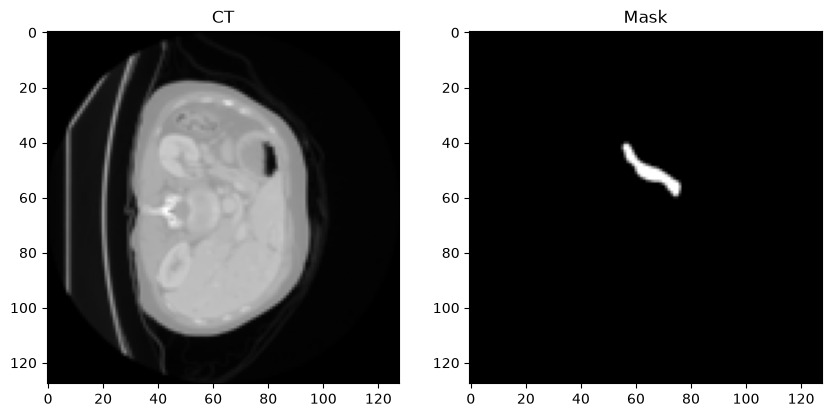

In [14]:
sample = train_ds[0]

image = sample["image"][0]
label = sample["label"][0]

slice_no = image.shape[2] // 2

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image[:,:,slice_no], cmap="gray")
plt.title("CT")

plt.subplot(1,2,2)
plt.imshow(label[:,:,slice_no], cmap="gray")
plt.title("Mask")

plt.show()

In [15]:
#building UNet model
model = UNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=3,   # <-- change from 2 to 3
    channels=(16,32,64,128,256),
    strides=(2,2,2,2),
    num_res_units=2
).to(device)

print(model)

UNet(
  (model): Sequential(
    (0): ResidualUnit(
      (conv): Sequential(
        (unit0): Convolution(
          (conv): Conv3d(1, 16, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1))
          (adn): ADN(
            (N): InstanceNorm3d(16, eps=1e-05, momentum=0.1, affine=False, bias=False, track_running_stats=False)
            (D): Dropout(p=0.0, inplace=False)
            (A): PReLU(num_parameters=1)
          )
        )
        (unit1): Convolution(
          (conv): Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          (adn): ADN(
            (N): InstanceNorm3d(16, eps=1e-05, momentum=0.1, affine=False, bias=False, track_running_stats=False)
            (D): Dropout(p=0.0, inplace=False)
            (A): PReLU(num_parameters=1)
          )
        )
      )
      (residual): Conv3d(1, 16, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1))
    )
    (1): SkipConnection(
      (submodule): Sequential(
        (0): ResidualUn

In [16]:
#Loss function and optimizer
loss_function = DiceLoss(
    to_onehot_y=True,
    softmax=True
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

dice_metric = DiceMetric(
    include_background=False,
    reduction="mean"
)

In [ ]:
os.makedirs("../models", exist_ok=True)

torch.save(
    model.state_dict(),
    "../models/pancreas_unet.pth"
)

print("Model Saved Successfully")

Model Saved Successfully


In [ ]:
sample = val_ds[0]

image = sample["image"].unsqueeze(0).to(device)

with torch.no_grad():
    prediction = model(image)

prediction = torch.argmax(prediction, dim=1).cpu().numpy()

print(prediction.shape)

(1, 128, 128, 128)


## Segmentation Completed

Loaded CT images

Built 3D U-Net

Trained pancreas segmentation model

 Saved trained model

The trained model will be used in the Feature Extraction notebook.

In [18]:
train_losses = []
val_dice_scores = []

epochs = 10

for epoch in range(epochs):

    model.train()
    epoch_loss = 0

    for batch in train_loader:
        ...
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)

    print(f"Epoch {epoch+1}: Loss = {avg_loss:.4f}")

    # Validation
    model.eval()

    with torch.no_grad():
        dice_metric.reset()

        for val_batch in val_loader:
            val_images = val_batch["image"].to(device)
            val_labels = val_batch["label"].to(device)

            val_outputs = model(val_images)

            dice_metric(y_pred=val_outputs, y=val_labels)

        dice = dice_metric.aggregate().item()
        val_dice_scores.append(dice)

        print(f"Validation Dice = {dice:.4f}")

Epoch 1: Loss = 0.6085
Validation Dice = 0.0014
Epoch 2: Loss = 0.6085
Validation Dice = 0.0014
Epoch 3: Loss = 0.6085
Validation Dice = 0.0014
Epoch 4: Loss = 0.6085
Validation Dice = 0.0014
Epoch 5: Loss = 0.6085
Validation Dice = 0.0014
Epoch 6: Loss = 0.6085
Validation Dice = 0.0014
Epoch 7: Loss = 0.6085
Validation Dice = 0.0014
Epoch 8: Loss = 0.6085
Validation Dice = 0.0014
Epoch 9: Loss = 0.6085
Validation Dice = 0.0014
Epoch 10: Loss = 0.6085
Validation Dice = 0.0014
